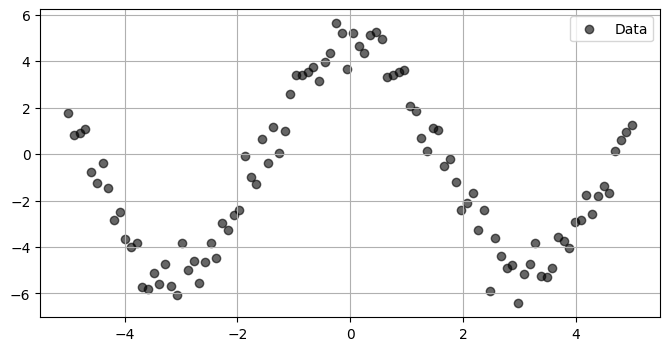

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, GradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve)
from sklearn.preprocessing import LabelEncoder

np.random.seed(42)

X = np.linspace(-5, 5, 100).reshape(-1, 1)
y = 5 * np.cos(X).ravel() + np.random.normal(0, 0.75, X.shape[0])

plt.figure(figsize=(8, 4))
plt.scatter(X, y, color='black', alpha=0.6, label='Data')
plt.legend()
plt.grid(True)
plt.show()

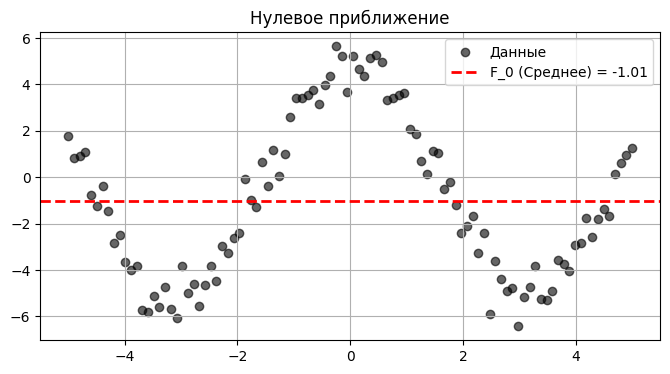

In [12]:
f_0 = np.mean(y)
F = np.full_like(y, f_0, dtype=np.float64)

plt.figure(figsize=(8, 4))
plt.scatter(X, y, color='black', alpha=0.6, label='Данные')
plt.axhline(f_0, color='red', linestyle='--', lw=2, label=f'F_0 (Среднее) = {f_0:.2f}')
plt.title("Нулевое приближение")
plt.legend()
plt.grid(True)
plt.show()

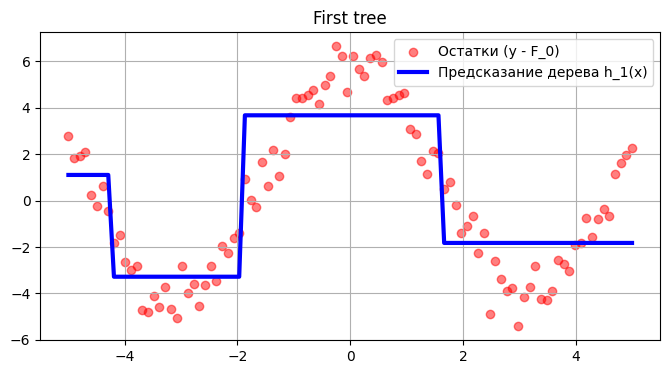

In [15]:
residuals_1 = y - F

tree_1 = DecisionTreeRegressor(max_depth=2, random_state=42)
tree_1.fit(X, residuals_1)

h_1 = tree_1.predict(X)

plt.figure(figsize=(8, 4))
plt.scatter(X, residuals_1, color='red', alpha=0.5, label='Остатки (y - F_0)')
plt.plot(X, h_1, color='blue', lw=3, label='Предсказание дерева h_1(x)')
plt.title("First tree")
plt.legend()
plt.grid(True)
plt.show()

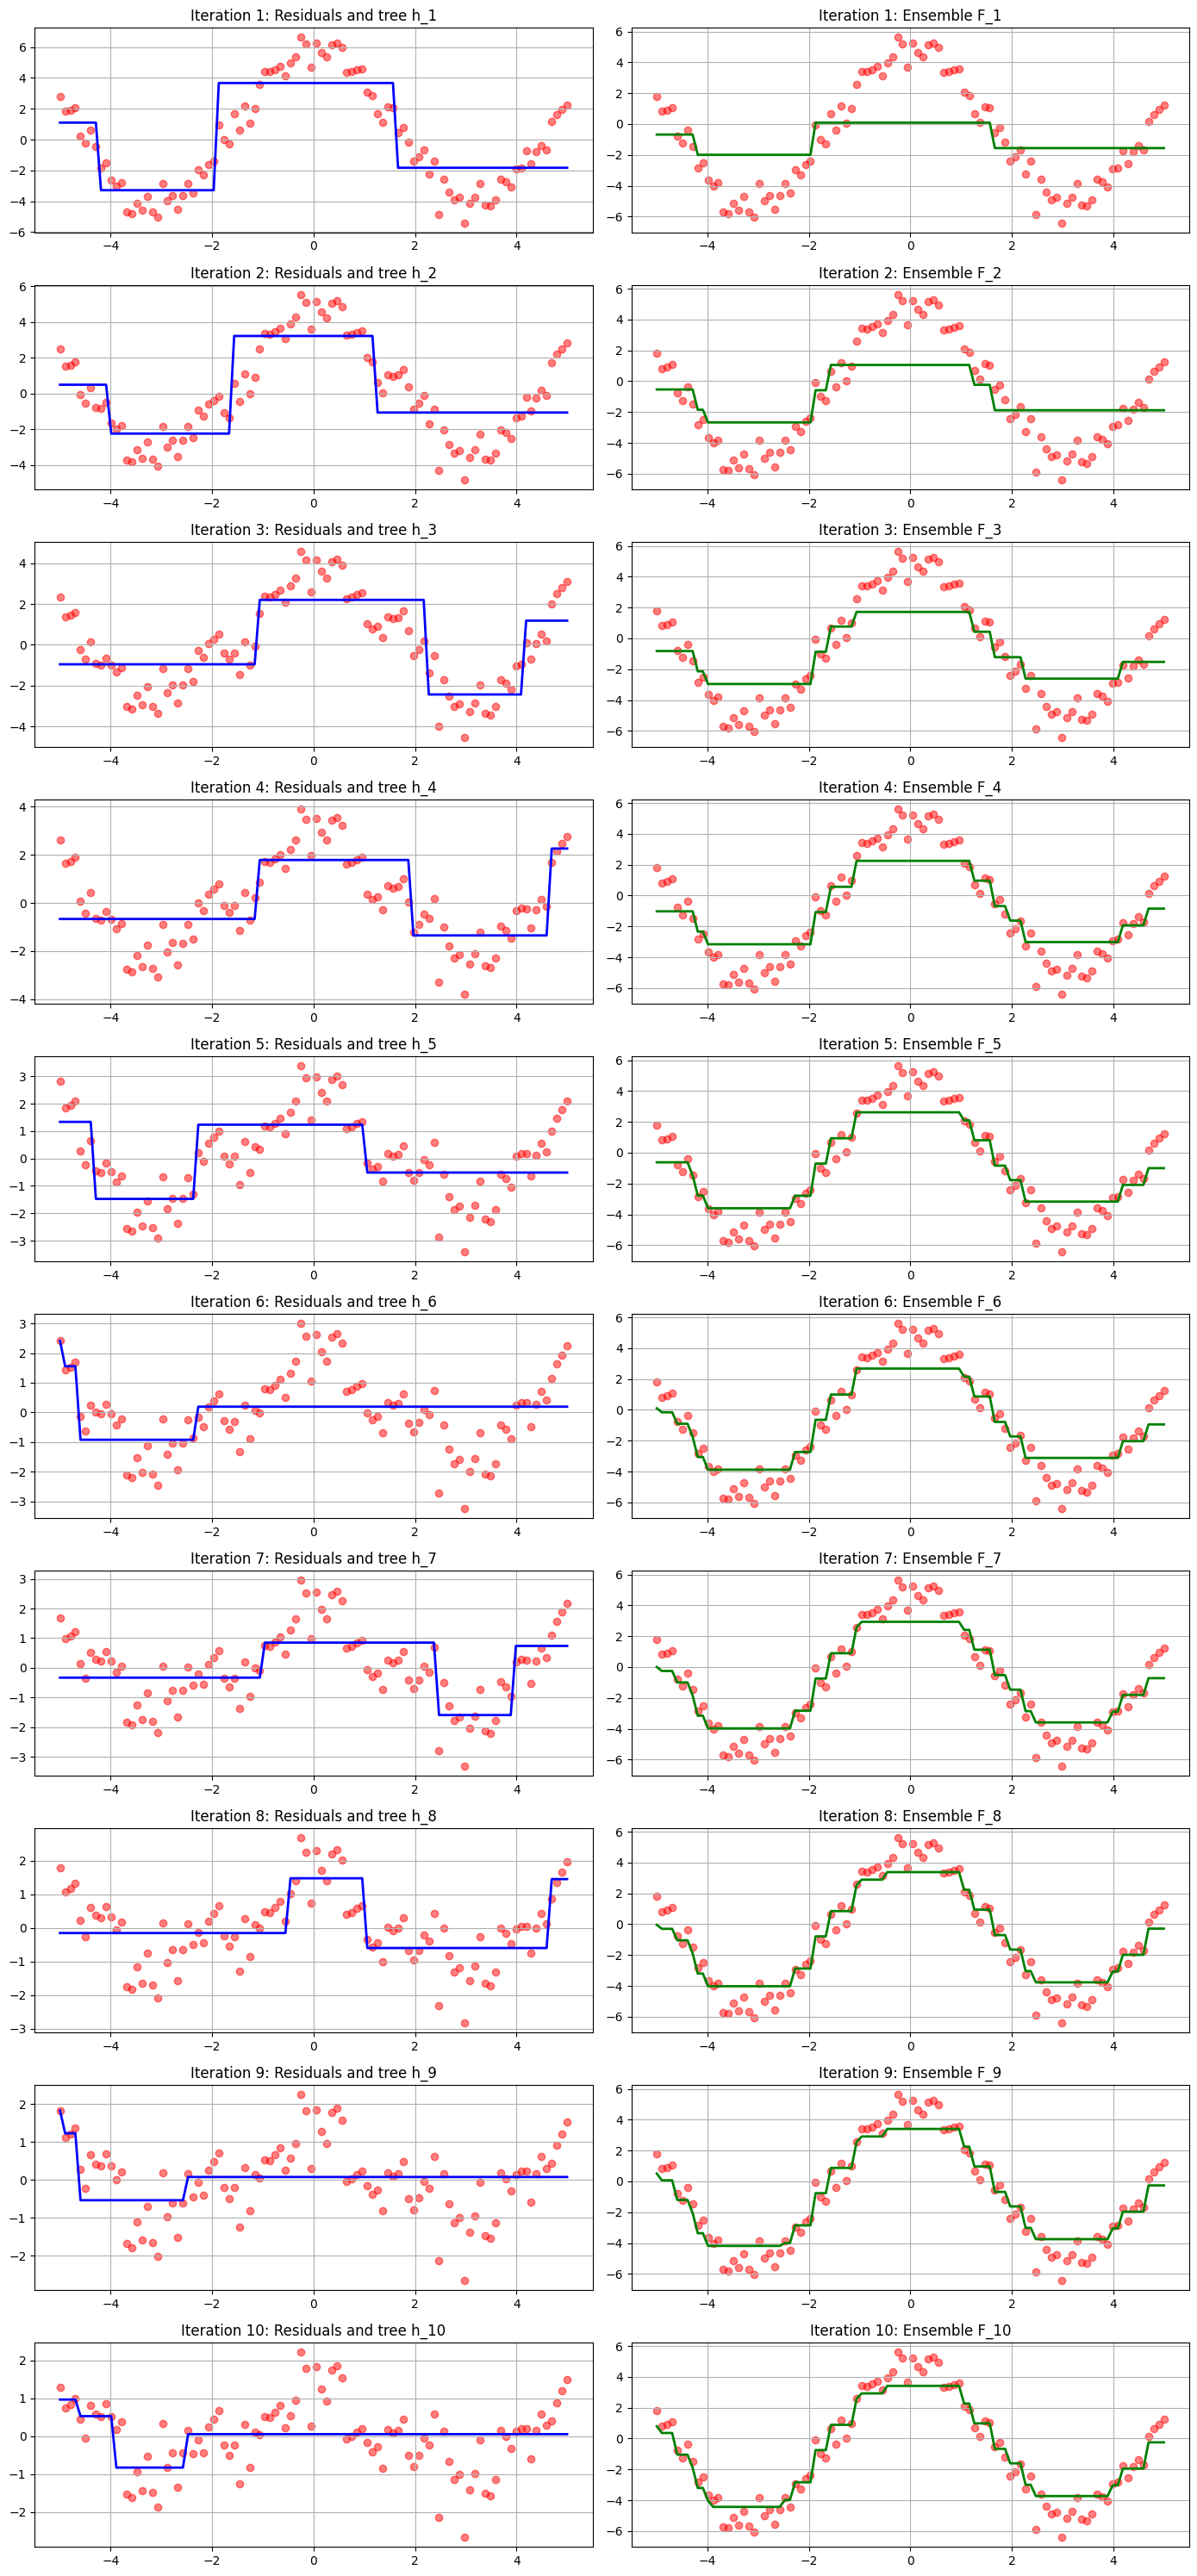

In [17]:
F = np.full_like(y, np.mean(y), dtype=np.float64)
n_estimators = 10
learning_rate = 0.3

fig, axes = plt.subplots(n_estimators, 2, figsize=(14, 3 * n_estimators))

for i in range(n_estimators):
    residuals = y - F
    tree = DecisionTreeRegressor(max_depth=2, random_state=42)
    tree.fit(X, residuals)
    h_x = tree.predict(X)

    axes[i,0].scatter(X, residuals, color='red', alpha=0.5)
    axes[i,0].plot(X, h_x, color='blue', lw=2)
    axes[i, 0].set_title(f"Iteration {i+1}: Residuals and tree h_{i+1}")
    axes[i, 0].grid(True)

    F = F + learning_rate * h_x

    axes[i, 1].scatter(X, y, color='red', alpha=0.5)
    axes[i, 1].plot(X, F, color='green', lw=2)
    axes[i, 1].set_title(f"Iteration {i+1}: Ensemble F_{i+1}")
    axes[i, 1].grid(True)

plt.tight_layout()
plt.show()

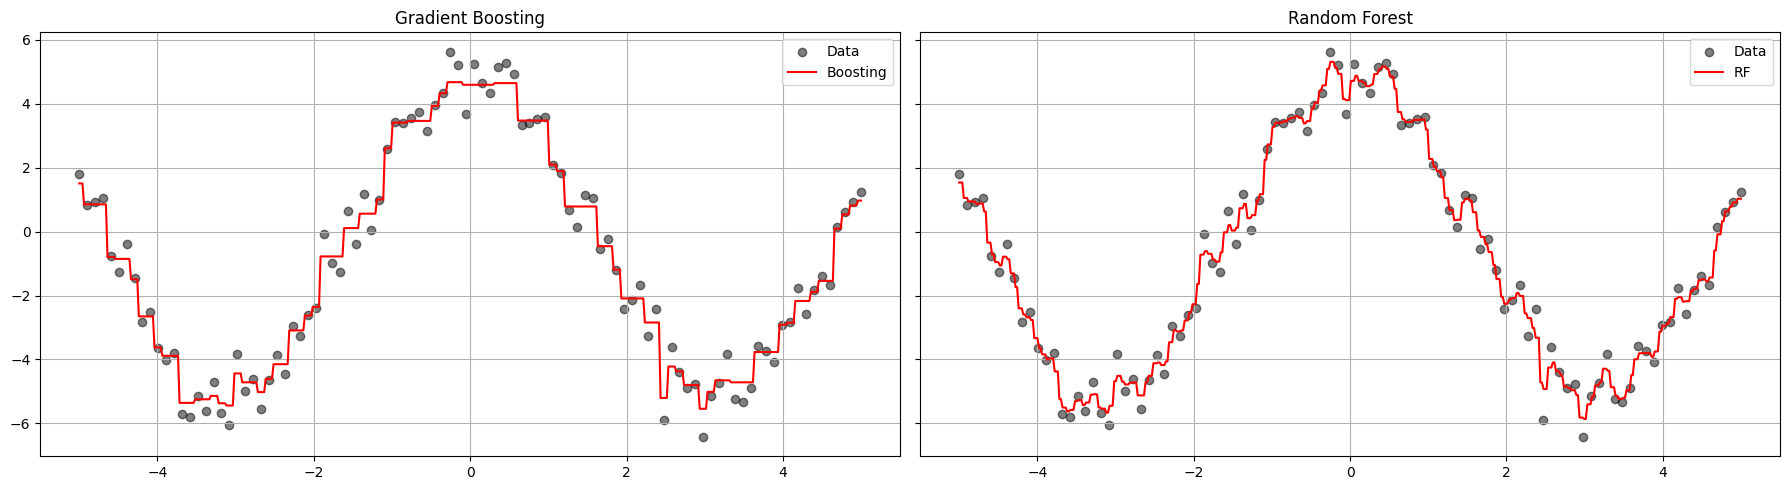

In [6]:
X_test = np.linspace(-5, 5, 500).reshape(-1, 1)


gbr = GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, max_depth=3, random_state=42)
gbr.fit(X, y)
gbr.predict(X_test)
y_pred_gbr = gbr.predict(X_test)

rf = RandomForestRegressor(n_estimators=50, random_state=42)
rf.fit(X, y)
y_pred_rf = rf.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharey=True)

axes[0].scatter(X, y, color='black', alpha=0.5, label='Data')
axes[0].plot(X_test, y_pred_gbr, color='red', label='Boosting')
axes[0].set_title("Gradient Boosting")
axes[0].legend()
axes[0].grid(True)

axes[1].scatter(X, y, color='black', alpha=0.5, label='Data')
axes[1].plot(X_test, y_pred_rf, color='red', label='RF')
axes[1].set_title("Random Forest")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [14]:
df = pd.read_csv('https://raw.githubusercontent.com/pandas-dev/pandas/master/doc/data/titanic.csv')

df = df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1)
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df['Sex'] = df['Sex'] = LabelEncoder().fit_transform(df['Sex'])  
df['Embarked'] = LabelEncoder().fit_transform(df['Embarked'])

In [15]:
X = df.drop('Survived', axis=1)
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [20]:
rf = RandomForestClassifier(n_estimators=50, random_state=42)
gbr = GradientBoostingClassifier(n_estimators=50, max_depth=3, learning_rate=0.1, random_state=42)

rf.fit(X_train, y_train)
gbr.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
gbr_pred = gbr.predict(X_test)

rf_proba = rf.predict_proba(X_test)[:, 1]
gbr_proba = gbr.predict_proba(X_test)[:, 1]


for name, pred, proba in [("Random Forest", rf_pred, rf_proba), 
                           ("Gradient Boosting", gbr_pred, gbr_proba)]:
    print(f"\n{name}:")
    print(f"  Accuracy:  {accuracy_score(y_test, pred):.4f}")
    print(f"  Precision: {precision_score(y_test, pred):.4f}")
    print(f"  Recall:    {recall_score(y_test, pred):.4f}")
    print(f"  F1-Score:  {f1_score(y_test, pred):.4f}")
    print(f"  ROC-AUC:   {roc_auc_score(y_test, proba):.4f}")


Random Forest:
  Accuracy:  0.8101
  Precision: 0.7778
  Recall:    0.7101
  F1-Score:  0.7424
  ROC-AUC:   0.8349

Gradient Boosting:
  Accuracy:  0.8101
  Precision: 0.8431
  Recall:    0.6232
  F1-Score:  0.7167
  ROC-AUC:   0.8256
